In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

os.makedirs("../figures", exist_ok=True)
sns.set_style("whitegrid")

close = pd.read_csv("../data/raw_close_prices.csv", index_col=0, parse_dates=True)
close = close.dropna(subset=["MSFT"]).ffill(limit=3).dropna()

weekly_close = close.resample("W-FRI").last()
if close.index[-1] < weekly_close.index[-1]:
    weekly_close = weekly_close.iloc[:-1]
weekly_ret = weekly_close.pct_change().dropna()

print(weekly_close.shape, weekly_ret.shape)

(877, 8) (876, 8)


In [2]:
summary = weekly_ret.describe().T
summary["skew"] = weekly_ret.skew()
summary["excess_kurtosis"] = weekly_ret.kurt()
print(summary.round(4))

        count    mean     std     min     25%     50%     75%     max    skew  \
MSFT    876.0  0.0041  0.0334 -0.1437 -0.0151  0.0040  0.0218  0.2175  0.3427   
IBM     876.0  0.0021  0.0346 -0.2604 -0.0145  0.0015  0.0193  0.1732 -0.3568   
GOOGL   876.0  0.0042  0.0385 -0.1292 -0.0191  0.0045  0.0244  0.2581  0.5829   
USDJPY  876.0  0.0007  0.0127 -0.0449 -0.0069  0.0010  0.0083  0.0639  0.0487   
GBPUSD  876.0 -0.0001  0.0120 -0.0856 -0.0073 -0.0004  0.0076  0.0614 -0.6449   
SP500   876.0  0.0024  0.0223 -0.1498 -0.0083  0.0034  0.0145  0.1210 -0.5283   
DOW     876.0  0.0021  0.0220 -0.1730 -0.0086  0.0029  0.0134  0.1284 -0.6371   
VIX     876.0  0.0128  0.1711 -0.4266 -0.0852 -0.0111  0.0780  1.3484  2.0078   

        excess_kurtosis  
MSFT             3.5734  
IBM              6.3808  
GOOGL            3.0703  
USDJPY           1.4523  
GBPUSD           6.2506  
SP500            5.3160  
DOW              8.6790  
VIX              9.7741  


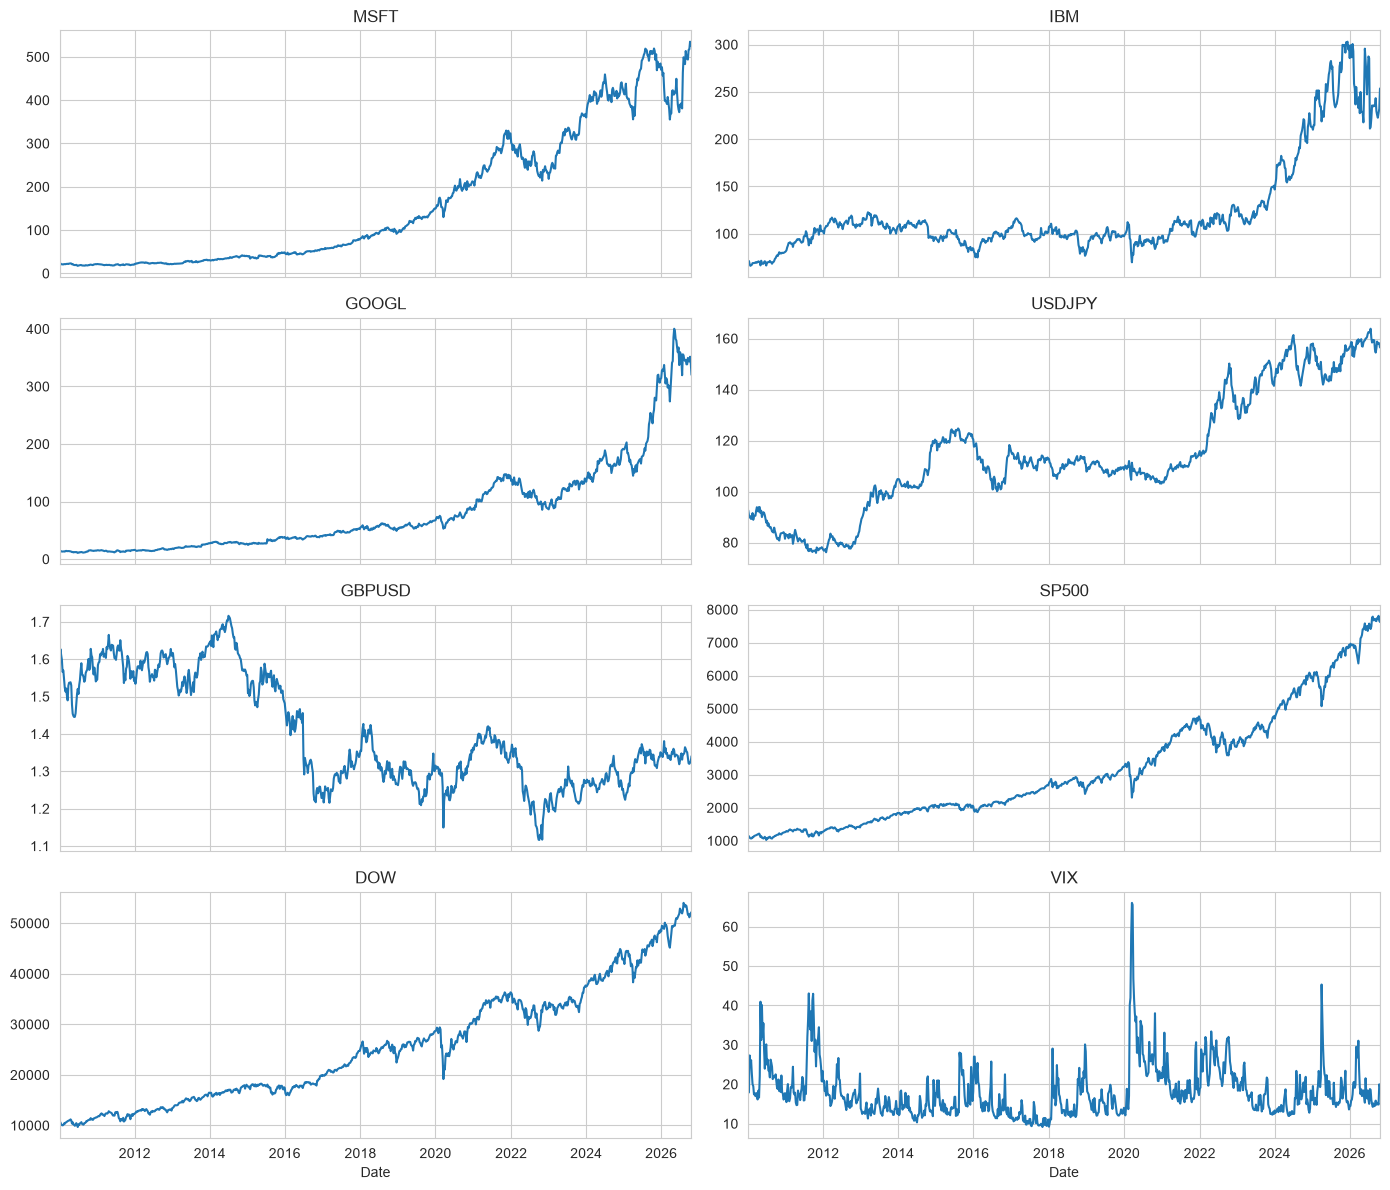

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, col in zip(axes.ravel(), weekly_close.columns):
    weekly_close[col].plot(ax=ax, title=col)
plt.tight_layout()
plt.savefig("../figures/01_weekly_prices.png", dpi=150)
plt.show()

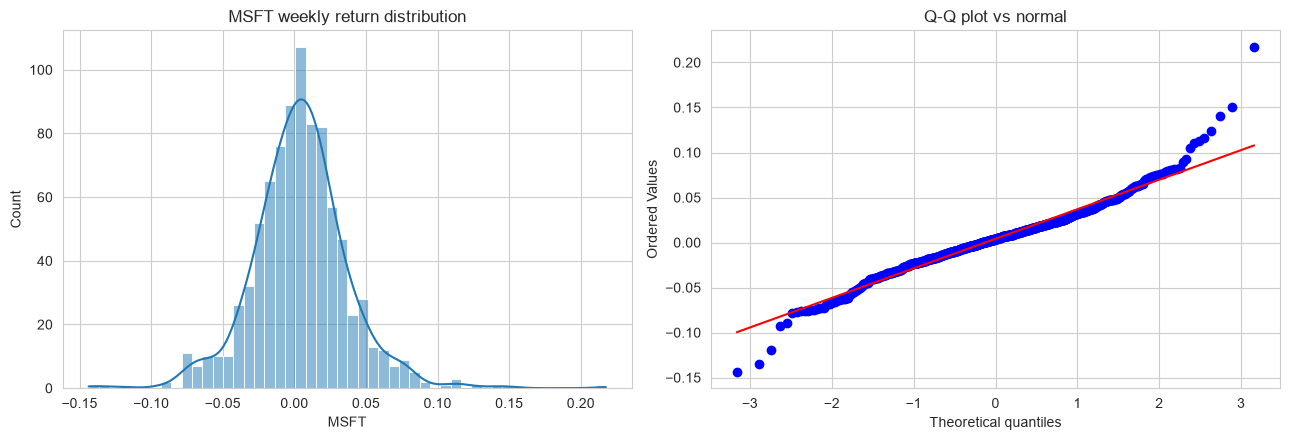

Jarque-Bera p-value: 4.16e-104

Best 5 weeks:
 Date
2026-07-31    0.217501
2015-04-24    0.150168
2026-04-17    0.139995
2023-03-17    0.124060
2022-11-11    0.116175
Name: MSFT, dtype: float64

Worst 5 weeks:
 Date
2015-01-30   -0.143705
2020-03-20   -0.135239
2013-07-19   -0.119708
2020-02-28   -0.092838
2016-02-05   -0.089490
Name: MSFT, dtype: float64


In [4]:
r = weekly_ret["MSFT"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(r, bins=50, kde=True, ax=ax[0])
ax[0].set_title("MSFT weekly return distribution")
stats.probplot(r, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot vs normal")
plt.tight_layout()
plt.savefig("../figures/02_msft_return_dist.png", dpi=150)
plt.show()

jb_stat, jb_p = stats.jarque_bera(r)
print(f"Jarque-Bera p-value: {jb_p:.2e}")

print("\nBest 5 weeks:\n", r.nlargest(5))
print("\nWorst 5 weeks:\n", r.nsmallest(5))

In [6]:
def adf_report(series, name):
    res = adfuller(series.dropna(), result_object=False)
    stat, p = res[0], res[1]
    print(f"{name:<22} ADF stat = {stat:8.3f}   p-value = {p:.4f}")

adf_report(weekly_close["MSFT"], "MSFT price")
adf_report(weekly_ret["MSFT"], "MSFT weekly return")

MSFT price             ADF stat =    0.878   p-value = 0.9928
MSFT weekly return     ADF stat =  -32.309   p-value = 0.0000


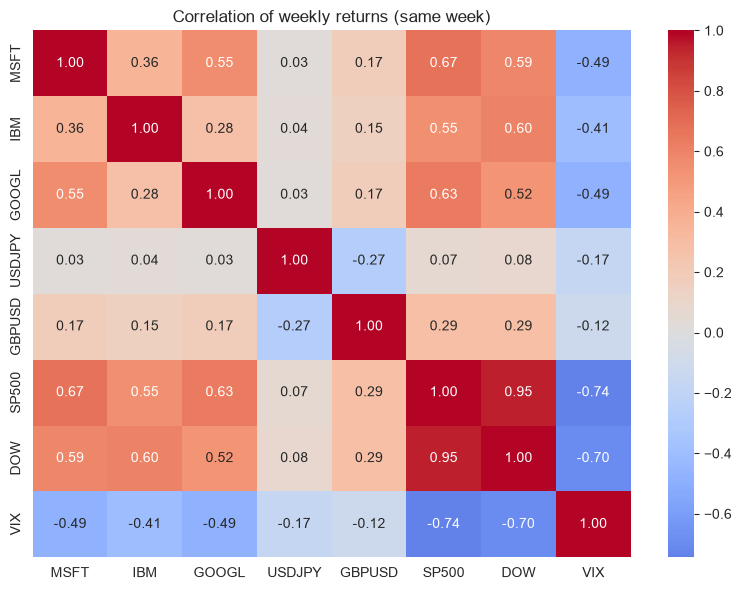

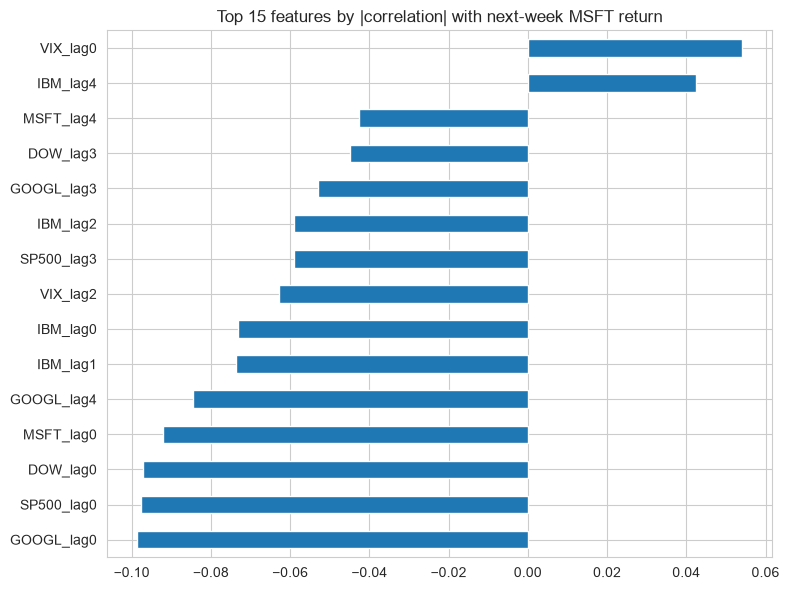

GOOGL_lag0   -0.099
SP500_lag0   -0.098
DOW_lag0     -0.097
MSFT_lag0    -0.092
GOOGL_lag4   -0.084
IBM_lag1     -0.074
IBM_lag0     -0.073
VIX_lag2     -0.063
SP500_lag3   -0.059
IBM_lag2     -0.059
VIX_lag0      0.054
GOOGL_lag3   -0.053
DOW_lag3     -0.045
MSFT_lag4    -0.043
IBM_lag4      0.042
Name: MSFT_next_week_ret, dtype: float64


In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(weekly_ret.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of weekly returns (same week)")
plt.tight_layout()
plt.savefig("../figures/03_corr_heatmap.png", dpi=150)
plt.show()

# Correlation of each lagged feature with NEXT week's MSFT return
ds = pd.read_csv("../data/dataset_base.csv", index_col=0, parse_dates=True)
corr_t = ds.corr()["MSFT_next_week_ret"].drop("MSFT_next_week_ret")
top = corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(15)

top.sort_values().plot.barh(
    figsize=(8, 6),
    title="Top 15 features by |correlation| with next-week MSFT return"
)
plt.tight_layout()
plt.savefig("../figures/04_feature_target_corr.png", dpi=150)
plt.show()
print(top.round(3))

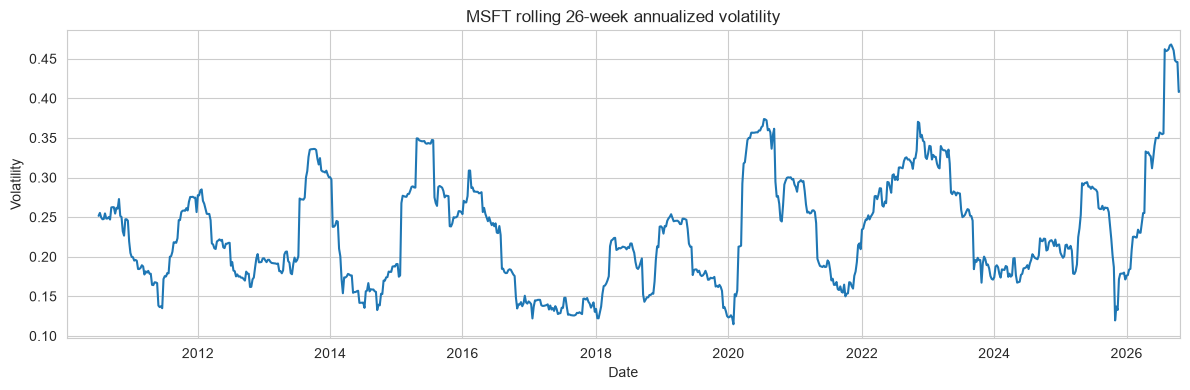

In [8]:
vol = weekly_ret["MSFT"].rolling(26).std() * np.sqrt(52)

plt.figure(figsize=(12, 4))
vol.plot()
plt.title("MSFT rolling 26-week annualized volatility")
plt.ylabel("Volatility")
plt.tight_layout()
plt.savefig("../figures/05_rolling_vol.png", dpi=150)
plt.show()

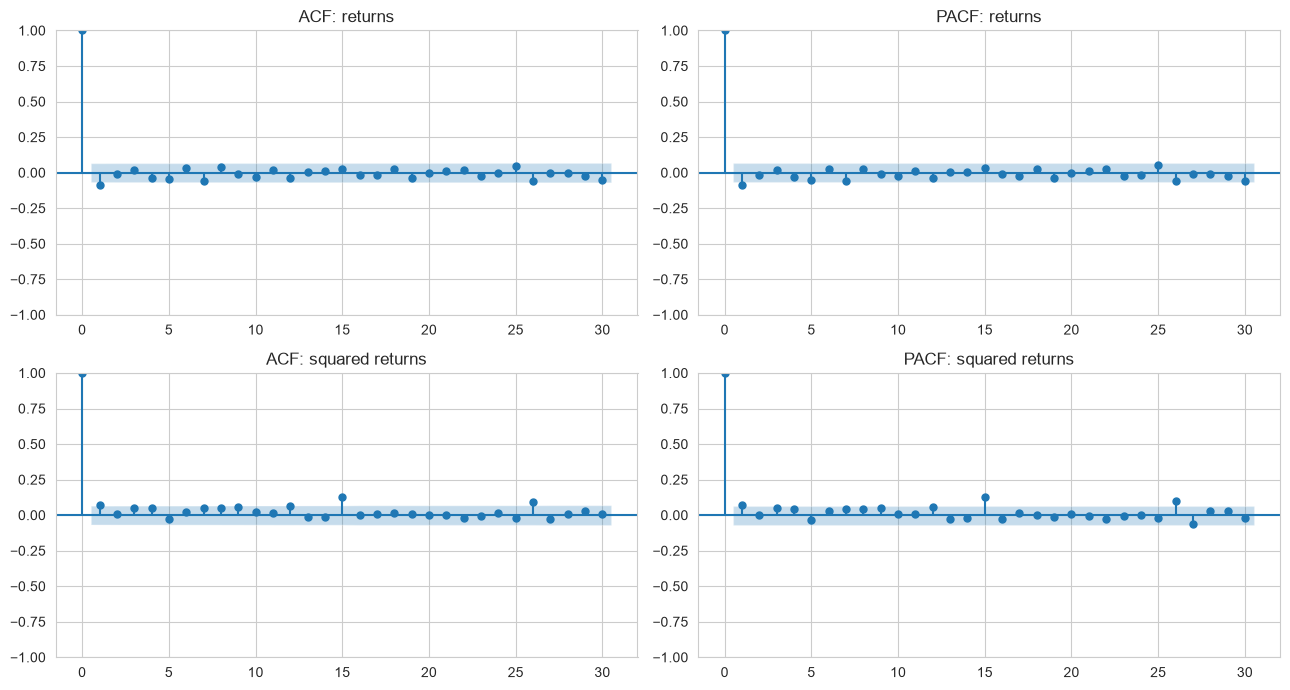

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(weekly_ret["MSFT"], lags=30, ax=ax[0, 0], title="ACF: returns")
plot_pacf(weekly_ret["MSFT"], lags=30, ax=ax[0, 1], method="ywm", title="PACF: returns")
plot_acf(weekly_ret["MSFT"] ** 2, lags=30, ax=ax[1, 0], title="ACF: squared returns")
plot_pacf(weekly_ret["MSFT"] ** 2, lags=30, ax=ax[1, 1], method="ywm", title="PACF: squared returns")
plt.tight_layout()
plt.savefig("../figures/06_acf_pacf.png", dpi=150)
plt.show()